In [12]:
%pip install ipympl

Note: you may need to restart the kernel to use updated packages.


## Data Setup

File paths along with Surface Colors Centers and Terrain information is defined.

In [ ]:
%matplotlib widget

import os
import urllib.request

#True if maps should be downloaded from repo
#False if maps are stored locally in Maps folder along with notebook
#   -Notebook
#   -Maps/ -[Maps]
ONLINE = False
#True if run on google colab
#False if run locally
COLAB = False

if COLAB:
    assert(ONLINE)

MAP_NAME = 'Omap-65958.png'

MAP_PATH = 'Maps/' + MAP_NAME
#Definitely a better way to do this but that is a fix-later problem
TERRAIN_PATH = 'Maps/' + MAP_NAME.split(".")[0] + '-alt' + '.' + MAP_NAME.split(".")[1]

STATE_PATH = ''
STATE_PATH_JSON = 'save_state.json'
STATE_PATH_pickle = 'save_state_bin'


if ONLINE:
    if COLAB:
        from google.colab import output
        output.enable_custom_widget_manager()

    REPO_URL = ("https://github.com/Swedishhammer/Orienteering/blob/main/")
    DIR_NAME = "Maps"
    os.makedirs(DIR_NAME, exist_ok=True)

    MAPS = [MAP_PATH, TERRAIN_PATH]
    for file_path in MAPS:
        if not os.path.exists(file_path):
            url = REPO_URL + file_path + "?raw=true"
            urllib.request.urlretrieve(url, file_path)

#colors
ol_color = (255, 193, 79)
ro_color = (255, 223, 163)
of_color = (255, 255, 255)
mf_color = (190, 244, 182)
rf_color = (131, 236, 112)
tf_color = (54, 223, 24)
wa_color = (70, 225, 225)
fb_color = (152, 177, 21)
road_color = (230, 172, 127)

#Incase detection doesn't work, I will manually block using this color
alt_bldg_color = (121, 121, 121)
oob_color = (237, 28, 36)
contour_color = (222, 134, 45)
path_color = (0, 0, 0)

#ax patches uses rgb float
#(204,0,204)
RING_COLOR = (0.8, 0, 0.8)
#OLD - Hard to see difference
#(255,51,255)
#COMPLETED_RING_COLOR = (1.0, 0.2, 1.0)
#(0,255,0)
COMPLETED_RING_COLOR = (0.0,1.0,0.0)


#Terrain Speed Multipliers are completely vibes-based
#Building tag applied after with gray_/building_mask
#Contour replaced later with surrounding surfaces
TERRAINS = {
    0: ('open land', ol_color, 1.0),
    1: ('rough open', ro_color, 0.9), 
    2: ('open forest', of_color, 0.8),
    3: ('medium forest', mf_color, 0.7),
    4: ('rough forest', rf_color, 0.5),
    5: ('tough forest', tf_color, 0.35),
    6: ('water', wa_color, 0.0),
    7: ('road', road_color, 1.1),
    8: ('path', path_color, 1.0),
    9: ('contour', contour_color, -1.0),
    10: ('forbidden', fb_color, 0.0),
    11: ('out of bounds', oob_color, 0.0),
    12: ('building', alt_bldg_color, 0.0)
}
#THIS NEEDS TO BE MANUALLY UPDATED IF TERRAINS IS CHANGED
#MAYBE FIX THIS TO BE AUTOMATIC LATER
#FORBIDDEN_ID = 9
#BUILDING_ID = 11

#Could probably be improved
FORBIDDEN_ID = next(ID for ID, (name, color, mult) in TERRAINS.items() if name == "forbidden")
BUILDING_ID = next(ID for ID, (name, color, mult) in TERRAINS.items() if name == "building")
OUT_OF_BOUNDS_ID = next(ID for ID, (name, color, mult) in TERRAINS.items() if name == "out of bounds")
CONTOUR_ID = next(ID for ID, (name, color, mult) in TERRAINS.items() if name == "contour")

IMPASSABLE_ID = [ID for ID, (name, color, mult) in TERRAINS.items() if mult == 0.0 ]


def speed_of(terrain_id):
    if not terrain_id in TERRAINS:
        return -1
    return TERRAINS[terrain_id][2]

def name_of(terrain_id):
    if not terrain_id in TERRAINS:
        return -1
    return TERRAINS[terrain_id][0]


AssertionError: 

## Color/Surface Labeling

Map is loaded from file path. Unique pixels (unique rgb) are minimized against their "distance" to color centers and results are distributed to remaining pixels. Assignments stored in a terrain grid (duplicate of map dimensions with terrain assignment id instead of rgb).

NOTE: Building color center excluded due to issues stemming from proximity to path color center. Building assignment is handled later.

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import matplotlib.image as mpimg
import numpy as np

def load_rgb(file_path):
    img = mpimg.imread(file_path)
    #Float to RGB int conversion if needed
    if img.dtype != np.uint8:
        img = (img*255).round().astype(np.uint8)
    #contig for efficient array ops, [..., :3] takes only rgb channels, ... disregards height/width dimensions
    return np.ascontiguousarray(img[..., :3])

#pack/unpack (de)compress rgb into single int
def pack(rgb):
    rgb = rgb.astype(np.int32)
    return (rgb[..., 0] << 16) | (rgb[..., 1] << 8) | (rgb[..., 2])

def unpack(px):
    return np.stack([(px >> 16) & 255, (px >> 8) & 255, (px & 255)], axis=-1)

#Adjust chunk - Note: at this scale of processing the chunking had no effect
def nearest_color_index(rgb, centers, chunk=50000):
    unique, uniq_inv = np.unique(pack(rgb), return_inverse = True)
    uniq = unpack(unique)
    best_match = np.empty(len(unique), np.int16)
    for i in range(0, len(unique), chunk):
        #Squared dist from px's color to color centers
        #None used for dimensionality matching
        color_dist = ((uniq[i:i + chunk, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
        best_match[i:i + chunk] = color_dist.argmin(axis=1)
    #Distribute index matches to px matching each unique
    #Converts from list to matrix before applying best_match to each inv index
    return best_match[uniq_inv.reshape(rgb.shape[:2])]

map_rgb = load_rgb(TERRAIN_PATH)
centers = np.array([terrain[1] for terrain in TERRAINS.values() if terrain[1] != alt_bldg_color])
terrain_grid = nearest_color_index(map_rgb, centers)

## Building vs Anti-aliasing

Critical

Mask of qualifying gray pixels* is created. Said mask is processed to identify "components" (clusters of color). Components/Clusters above a threshold are deemed to be buildings and labeled as such in the terrain grid.

*Based on parameters governing "grayness" that are manually set but based on building color center.

In [15]:
from scipy import ndimage

#Currently roughly based on alt_bldg_color
GRAY_MIN = 100
GRAY_MAX = 150
GRAY_BOUND = 25

BUILDING_MIN = 12

GRAY_MASK = (
    (map_rgb.min(axis=2) > GRAY_MIN) &
    (map_rgb.max(axis=2) < GRAY_MAX) & 
    ((map_rgb.max(axis=2) - map_rgb.min(axis=2)) < GRAY_BOUND)
)

#Consider altering structure if it doesn't succeed initially
components, num_components = ndimage.label(GRAY_MASK, structure=np.ones((3,3)))

sizes = np.bincount(components.ravel())
sizes[0] = 0

building_mask = sizes[components] >= BUILDING_MIN

#Apply building_mask to current terrain_grid - overwrites other classifications for pixels
terrain_grid[building_mask] = BUILDING_ID

Visualization - Not Critical

"original" shows the terrain map the simulator uses for terrain assignemnt which is a manually modified version of the shown/true map.

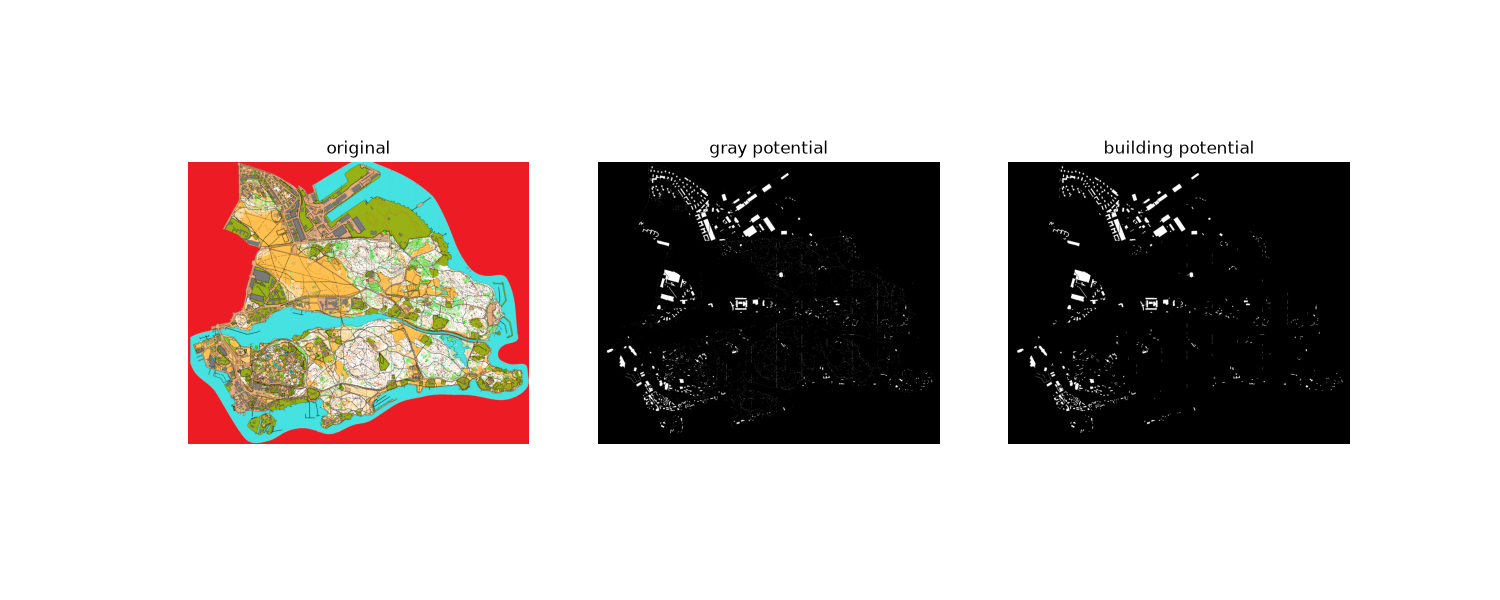

In [16]:
fig2, axes = plt.subplots(1, 3, figsize=(15,6))

axes[0].imshow(map_rgb)
axes[0].set_title("original")

axes[1].imshow(GRAY_MASK, cmap="gray")
axes[1].set_title("gray potential")

axes[2].imshow(building_mask, cmap="gray")
axes[2].set_title("building potential")

for ax in axes:
    ax.axis("off")

plt.tight_layout
plt.show()

## Contours

Visualization - Not Critical

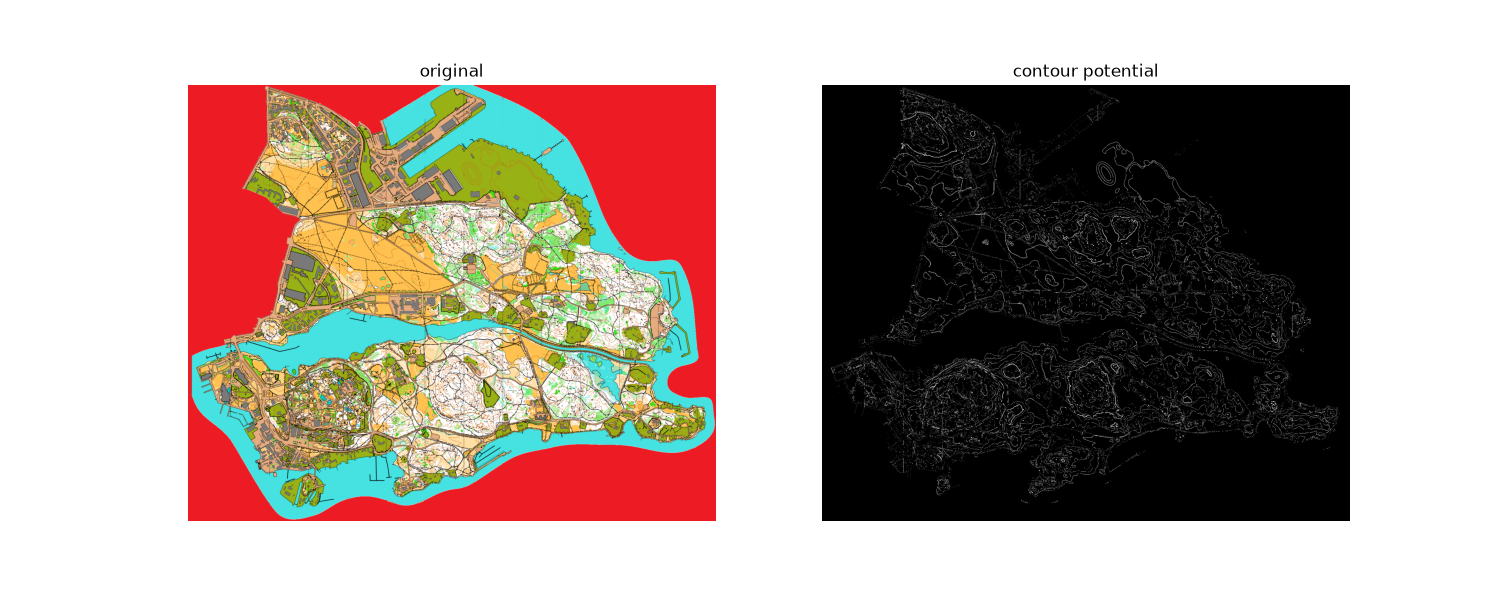

In [17]:
CONTOUR_MASK = terrain_grid == CONTOUR_ID

fig2, axes = plt.subplots(1, 2, figsize=(15,6))

axes[0].imshow(map_rgb)
axes[0].set_title("original")

axes[1].imshow(CONTOUR_MASK, cmap="gray")
axes[1].set_title("contour potential")

for ax in axes:
    ax.axis("off")

plt.tight_layout
plt.show()

Critical

Pixels with contour terrain assignment are reassigned to the terrain id of the closest* non-contour pixel.

*Euclidean Distance

In [18]:
#CHANGES CONTOUR PIXELS TO BE THE SAME AS NEAREST NON-CONTOUR SURFACE
#
from scipy import ndimage
import numpy as np

CONTOUR_MASK = terrain_grid == CONTOUR_ID

#Finds nearest non-contour pixel
_, indices = ndimage.distance_transform_edt(CONTOUR_MASK, return_indices=True)

terrain_grid[CONTOUR_MASK] = terrain_grid[indices[0][CONTOUR_MASK],indices[1][CONTOUR_MASK]]

## Forbidden vs Anti-aliasing

Critical

Mask of forbidden pixels*. Said mask is processed to identify "components" (clusters of color) checking non-diagonal neighbouring pixels. Components/Clusters below a threshold are deemed to likely not be forbidden areas** and are reassigned to the terrain id of the closest*** non-forbidden pixel.

*Pixels with forbidden terrain assignment. \**Often misidentified anti-aliased pixels, especially along paths ***Euclidean Distance

In [19]:
from scipy import ndimage
import numpy as np

FORBIDDEN_MIN = 16
#FORBIDDEN_STRUCTURE = np.ones((3,3))
FORBIDDEN_STRUCTURE = [[0,1,0],
                       [1,1,1],
                       [0,1,0]]

FORBIDDEN_MASK = terrain_grid == FORBIDDEN_ID

components, num_components = ndimage.label(FORBIDDEN_MASK, structure=FORBIDDEN_STRUCTURE)


sizes = np.bincount(components.ravel())
sizes[0] = 0

forbidden_mask = sizes[components] >= FORBIDDEN_MIN

inv_forbidden_mask = FORBIDDEN_MASK & ~forbidden_mask
_, indices = ndimage.distance_transform_edt(inv_forbidden_mask, return_indices=True)

terrain_grid[inv_forbidden_mask] = terrain_grid[indices[0][inv_forbidden_mask],indices[1][inv_forbidden_mask]]

Visualization - Not Critical

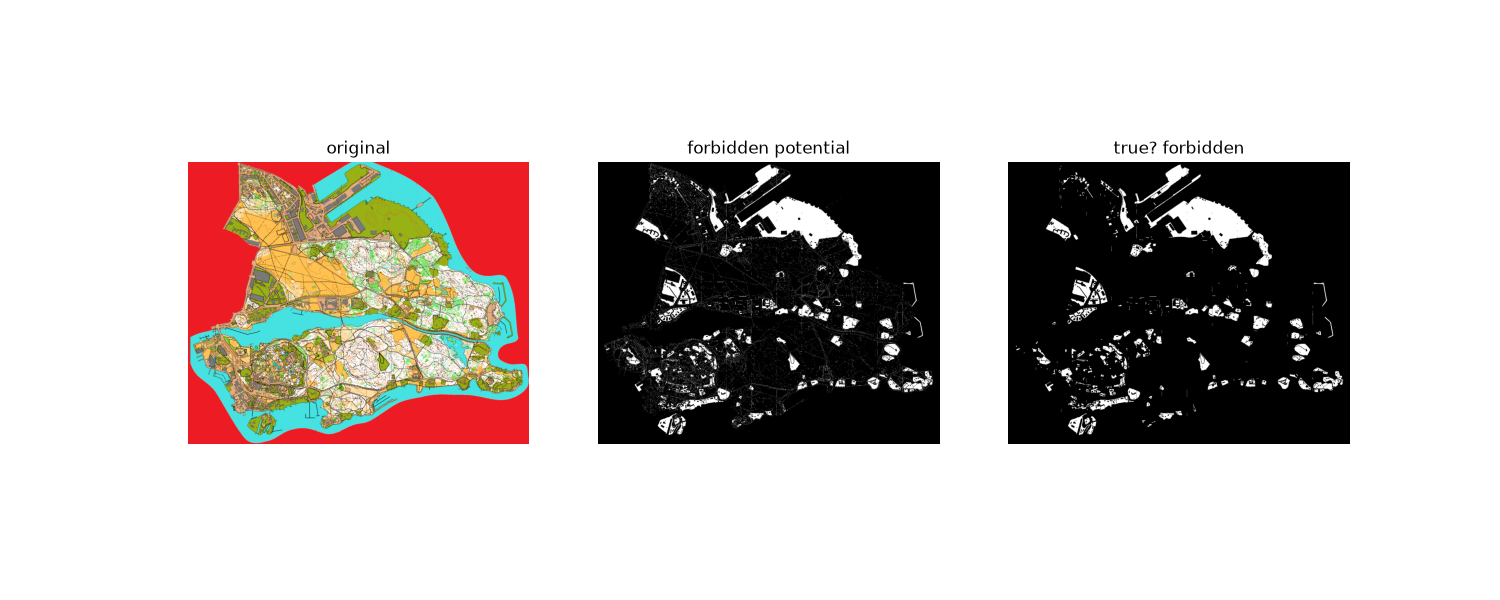

In [20]:
fig2, axes = plt.subplots(1, 3, figsize=(15,6))

axes[0].imshow(map_rgb)
axes[0].set_title("original")

axes[1].imshow(FORBIDDEN_MASK, cmap="gray")
axes[1].set_title("forbidden potential")

axes[2].imshow(forbidden_mask, cmap="gray")
axes[2].set_title("true? forbidden")

for ax in axes:
    ax.axis("off")

plt.tight_layout
plt.show()

## Control Rings

Rings randomly generated based on parameters with the conditions that no part of the ring touches a blocked (0.0 speed) pixel and do not overlap with another ring. Rings are naively picked and evaluated -> requesting more rings than a typical expected of an orienteering map (~20) and/or using a map with significant blocked areas leads to significantly long run times for this cell.

Note: Currently the simulator doubles the radius of rings when drawing them on the map to improve visibility -> some rings appear to overlap or touch blocked pixels however the portion of the ring being checked for completion still meets conditions.

In [ ]:
RING_COUNT = 10
RING_RADIUS = 14
RING_THICKNESS = 1.5

RING_SPACING = 40


def check_ring(center, radius, thickness):
    height, width = terrain_grid.shape
    center_y, center_x = center

    y, x = np.ogrid[:height, :width]
    squared_dist = (y - center_y)**2 + (x - center_x)**2

    inner = max(0, radius - thickness/2)
    outer = radius + thickness/2

    ring_mask = (squared_dist >= inner**2) & (squared_dist <= outer**2)

    ring_terrain = terrain_grid[ring_mask]
    passable = ~np.isin(ring_terrain, list(IMPASSABLE_ID))

    #Returns true only if no part of the ring overlaps impassable surface
    #Change to .any() if this requirement proves too restrictive
    return passable.all()

#max_attempts is to prevent it from trying forever if not possible
#Will return what it managed to generate so far
def generate_checkpoints(count, radius, thickness, min_spacing, max_attempts=10000):
    height, width = terrain_grid.shape

    map_margin = int(np.ceil(radius + thickness/2))
    if np.min([height, width]) <= 2 * map_margin:
        print("Radius or Thickness is too big for map")
        return []
    
    checkpoints = []
    for _ in range(max_attempts):
        if len(checkpoints) >= count:
            break

        center_y = np.random.randint(map_margin, height - map_margin)
        center_x = np.random.randint(map_margin, width - map_margin)

        if check_ring((center_y, center_x), radius, thickness) and not any((center_y - ry)**2 + (center_x - rx)**2 < min_spacing**2 for ry, rx in checkpoints):
            checkpoints.append((center_y, center_x))

    if len(checkpoints) < count:
        print(f'Generated {len(checkpoints)} of {count} requested.')

    return checkpoints

def check_checkpoints(checkpoints, completed, player_loc):
    dist = checkpoints - player_loc
    squared_dist = np.sum(dist**2, axis=1)

    inside_checkpoint = (~completed & (squared_dist <= RING_RADIUS**2))
    completed[inside_checkpoint] = True
    return checkpoints[inside_checkpoint]

## Map Control/Game

The interactive simulation!
Current surface (and associated speed multiplier) are shown at the top of the map. Moves onto blocked surfaces are not allowed (doing so will lead to no change). Saving/loading of the game state (map, position, zoom[via bounds], completed checkpoints) is done locally, either through JSON or pickle (USE_JSON controls which).

Note: There is no win screen. The win is expressed in the log below the map but you are free to continue exploring the map.

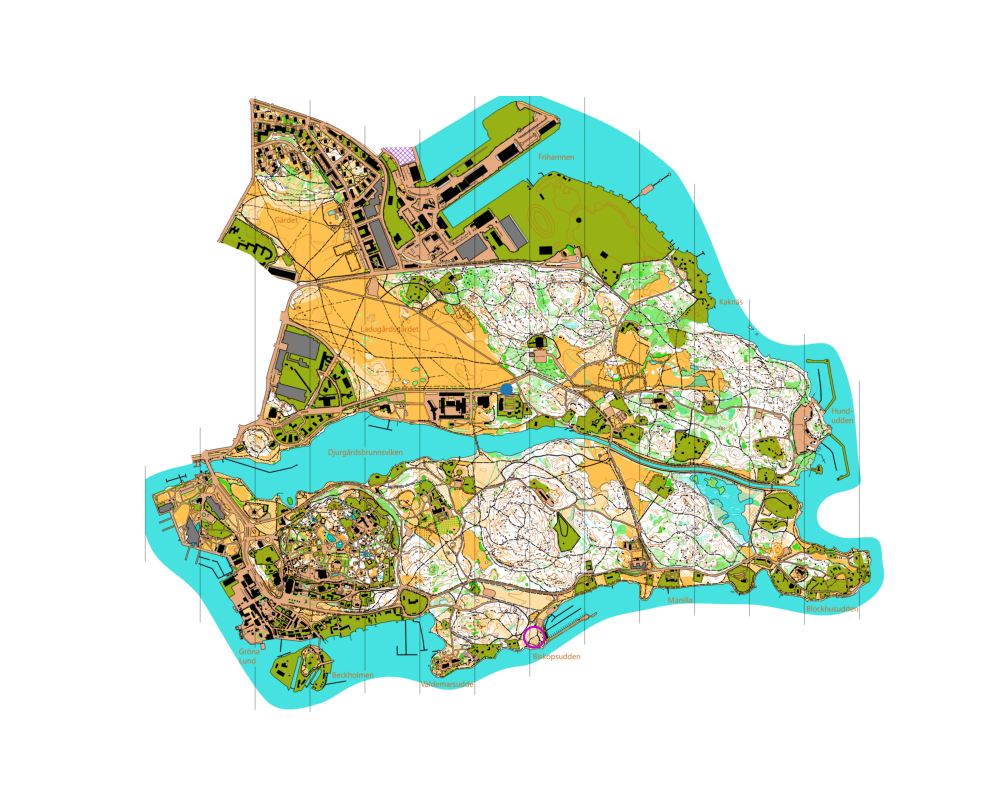

Output()

In [38]:
import os, json, pickle

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import ipywidgets as widgets
from IPython.display import display

PLAYER_SIZE = 8

#Allows program to use 'o' for zoom instead of matplotlib
plt.rcParams['keymap.zoom'] = []
#matplotlib no longer accepts 's' to avoid conflict
plt.rcParams['keymap.save'] = ['ctrl+s']
#matplotlib no longer accepts 'l' to avoid conlict
plt.rcParams['keymap.yscale'] = []

terrain = terrain_grid
#Allows printing within callbacks for debugging, disable later
DEBUG = True
output = widgets.Output()

#*args means arbitary number of arbitary argument
def log(*args):
    if DEBUG:
        with output:
            print(*args)

#circle/marker's movement
#base_speed in m/s
base_speed = 3.3
#pix/m, 0.617... is based on 65958 & needs to be recalculated for each
scale_mult = 0.61715

#Portion of the screen treated as margin
#0.2 -> if circle moves within outer 20%, map view will shift accordingly
#DON'T SET TO >= 0.5
border_margin_factor = 0.2

#Strength of the zoom, in/out
zoom_factor = 1.5

# [left, right, up, down]
move_keys = ['4', '6', '8', '2']


map_image = mpimg.imread(MAP_PATH)

fig, ax = plt.subplots(figsize=(10,8))
ax.imshow(map_image)

#Disables "plot" appearance
ax.set_axis_off()
fig.canvas.header_visible = False

player, = ax.plot([1000],[800],
                  marker="o",
                  markersize=PLAYER_SIZE)
#Used to get unstuck
#
backup_x = 1000
backup_y = 800
#checkpoints
def draw_checkpoints():
    for i in range(len(checkpoints)):
        c = checkpoints[i]
        #log("c",c)
        ring_color = COMPLETED_RING_COLOR if checkpoints_completed[i] else RING_COLOR

        ring = plt.Circle((c[1], c[0]), 2*RING_RADIUS, color=ring_color, fill=False, linewidth=RING_THICKNESS)
        ax.add_patch(ring)

checkpoints = np.asarray(generate_checkpoints(RING_COUNT, RING_RADIUS, RING_THICKNESS, RING_SPACING))
checkpoints_completed = np.zeros(len(checkpoints), dtype=bool)
draw_checkpoints()

#Uses player current position if coordinates not given
def terrain_here(x=None,y=None):
    if x == None:
        x = player.get_xdata()[0]
    if y == None:
        y = player.get_ydata()[0]
    return terrain[int(y), int(x)]

#DB versions of terrain call functions
"""
def terrain_here():
    return terrain.at(int(player.get_xdata()[0]), int(player.get_ydata()[0]))

def terrain_here(x,y):
    return terrain.at(int(x), int(y))
"""

#For debugging purposes
def update_title():
    t = terrain_here()
    ax.set_title(f'{name_of(t)} (speed: {speed_of(t):.1f})')

#STATE Related
#JSON - 763B vs 419B - bin(pickle)
#Savings are insignificant given project (not actively sending save data) and
#   pickle presents risk for malicious actions (effectively runs binary)
#True-JSON : False-pickle
USE_JSON = True
if (USE_JSON):
    STATE_PATH = STATE_PATH_JSON
else:
    STATE_PATH = STATE_PATH_pickle
def save_state():
    state = {
        'map': MAP_PATH,
        'player_loc': [float(player.get_xdata()[0]), float(player.get_ydata()[0])],
        'xbound': list(ax.get_xbound()),
        'ybound': list(ax.get_ybound()),
        'checkpoints': checkpoints.tolist(),
        'checkpts_completed': checkpoints_completed.tolist()
    }
    #Maybe change to pickle to match class serialization
    if (USE_JSON):
        with open(STATE_PATH, 'w') as file:
            json.dump(state, file, indent = 2)
    else:
        with open(STATE_PATH, 'wb') as file:
            pickle.dump(state, file)
    
    log('saved', state)

def load_state():
    if not os.path.exists(STATE_PATH):
        return False

    if (USE_JSON):
        with open(STATE_PATH) as file:
            state = json.load(file)
    else:
        with open(STATE_PATH, 'rb') as file:
            state = pickle.load(file)
    
    #Change this to switch map to MAP_PATH in future
    if state.get('map') != MAP_PATH:
        return False
    log("x_location", [state['player_loc'][0]])
    log("y_location", [state['player_loc'][1]])
    log("xbound", *state['xbound'])
    log("ybound", *state['ybound'])
    player.set_data([state['player_loc'][0]], [state['player_loc'][1]])
    ax.set_xbound(*state['xbound'])
    ax.set_ybound(*state['ybound'])
    #This only sets local variables, doesn't update the globals
    checkpoints = np.array(state['checkpoints'])
    checkpoints_completed = np.array(state['checkpts_completed'])
    return checkpoints, checkpoints_completed


#KEY/MOVEMENT Related
def on_press(event):
    key = event.key
    #log('pressed:', key)

    if key == 'i' or key == 'o':
        zoom(key)
    elif key == 's':
        save_state()
    elif key == 'l':
        global checkpoints, checkpoints_completed
        load_result = load_state()
        if not load_result == None:
            checkpoints, checkpoints_completed = load_result
        draw_checkpoints()
    elif key == 'u':
        #unstuck
        player.set_data([backup_x], [backup_y])
    elif key in move_keys:
        move(key)

    #Shows current surface + speed
    update_title()
    fig.canvas.draw_idle()

#step_factor is to allow partial steps to get out of stuck positions
#   Position was reached with a low terrain speed but moved onto terrain with high speed
#   With whole step, potentially impossible to reverse move that was just done.
def move(key, step_factor=1):
    x = player.get_xdata()[0]
    y = player.get_ydata()[0]
    step = base_speed * scale_mult * speed_of(terrain_here()) * step_factor
    #log("step", step)
    if key == move_keys[0]:
        x -= step
    elif key == move_keys[1]:
        x += step
    # High y is down on plot
    elif key == move_keys[2]:
        y -= step
    elif key == move_keys[3]:
        y += step

    new_terrain = terrain_here(x,y)
    
    #Checking for 0.0 speed
    if new_terrain in IMPASSABLE_ID:
        if (step_factor > 0.5):
            move(key, step_factor - 0.1)
        else:
            log("invalid move")
        #log("impassable terrain:", name_of(new_terrain))
        #log("problem pixel", x, y)
    else:
        player.set_data([x], [y])
        #log('player at:', x, y)
        #log('x_bounds:', ax.get_xbound())
        #log('y_bounds:', ax.get_ybound())
        new_complete = check_checkpoints(checkpoints, checkpoints_completed, (y,x))
        if len(new_complete) == 1:
            draw_checkpoints()
            if all(checkpoints_completed):
                log("You Completed All Checkpoints!!!")
        margin_correct()


def zoom(key):
    xbound_min, xbound_max = ax.get_xbound()
    xbound_min = int(xbound_min)
    xbound_max = int(xbound_max)
    xbound_diff = (xbound_max - xbound_min) / 2
    ybound_min, ybound_max = ax.get_ybound()
    ybound_min = int(ybound_min)
    ybound_max = int(ybound_max)
    ybound_diff = (ybound_max - ybound_min) / 2
    if key == 'i':
        xbound_min += xbound_diff / zoom_factor
        xbound_max -= xbound_diff / zoom_factor
        ybound_min += ybound_diff / zoom_factor
        ybound_max -= ybound_diff / zoom_factor
    if key == 'o':
        xbound_min -= xbound_diff * zoom_factor
        xbound_max += xbound_diff * zoom_factor
        ybound_min -= ybound_diff * zoom_factor
        ybound_max += ybound_diff * zoom_factor
    ax.set_xbound(xbound_min, xbound_max)
    ax.set_ybound(ybound_min, ybound_max)
    margin_correct()
    
def margin_correct():
    x = player.get_xdata()[0]
    y = player.get_ydata()[0]

    xbound_min, xbound_max = ax.get_xbound()
    xbound_min = int(xbound_min)
    xbound_max = int(xbound_max)
    ybound_min, ybound_max = ax.get_ybound()
    ybound_min = int(ybound_min)
    ybound_max = int(ybound_max)

    xborder_margin = (xbound_max - xbound_min) * border_margin_factor
    yborder_margin = (ybound_max - ybound_min) * border_margin_factor

    if x - xbound_min < xborder_margin:
        diff = xbound_min + xborder_margin - x
        xbound_min -= diff
        xbound_max -= diff
    if xbound_max - x < xborder_margin:
        diff = x - (xbound_max - xborder_margin)
        xbound_min += diff
        xbound_max += diff
    if y - ybound_min < yborder_margin:
        diff = ybound_min + yborder_margin - y
        ybound_min -= diff
        ybound_max -= diff
    if ybound_max - y < yborder_margin:
        diff = y - (ybound_max - yborder_margin)
        ybound_min += diff
        ybound_max += diff

    ax.set_xbound(xbound_min, xbound_max)
    ax.set_ybound(ybound_min, ybound_max)

fig.canvas.mpl_connect('key_press_event', on_press)


plt.show()
display(output)

## Reflection

Programming this simulation has given me a better understanding of how one can both interact and store data. In two cases I compared two development decisions pertaining to how the data would be handled. In the first case I determined when data was to be processed and assigned a terrain, either all at once or just in the region around the player. Originally the latter seemed enticing, however it came with some downsides that ended up outweighing the benefits, leading to me picking the former. Namely, despite the cold start time being faster, there was a chance for additional stuttering while moving quickly and it made placing checkpoints difficult as there was no good way to check if they were reasonable (not placed on a building, forbidden area, etc…). In the second case I compared using JSON vs. pickle for saving and loading the game state. JSON was shown to be relatively large (almost double the size of the pickle save file) however they were both very small (<1KB). I also considered that I was not intending to send game states to other players live thus the size difference was not significant and recognized that there were some added risks with pickle as it effectively executes the save file thus creating a potential malware risk.

As for the interaction with the data, the original implementation relied more heavily on for loops, especially in the terrain assignment section. This led to somewhat significantly long run times. After some research as well as overlap with my Machine Learning course, I switched the for loops out for a collection of numpy operations which performed better and would be the final version of this section.

This project definitely has its shortcomings and there are a couple parts that I originally believed would not be hard to implement before I realized the challenge in front of me. Originally I planned on allowing for the use of multiple maps before realizing how much work was needed to get each map to function - color centers have to be picked manually, the map has to be manually edited into a terrain map to help the simulation and cluster parameters (such as for buildings or forbidden areas) have to be tweaked manually while reviewing the resultant terrain map. Even after all that, there are still inaccuracies such as some walls being misidentified as paths and some paths not being identified due to being small and dashed.
	
This project helped me appreciate how much data us humans are processing when looking at such a map. A person knows the difference between a building, a wall and a path simply by looking at it and the surrounding context in a way that is potentially possible for the computer but only after significant programming and computation. Additionally, I quickly came to realize that data that is ideal for humans to process is not the same as for computers. Humans often prefer anti-aliasing which, if done correctly, should not hamper, if not help, with reading the map. Computers on the other hand, at least my program, do horribly with processing anti-aliased data and would be much better off with sharp edges.
